# Spectral Clustering: A Detailed Introduction

## What is Spectral Clustering?

**Spectral clustering** is a powerful unsupervised learning algorithm used to partition a dataset into meaningful groups or clusters. Unlike traditional clustering methods such as K-Means, which rely on minimizing intra-cluster distances based on Euclidean space, spectral clustering uses the properties of the data represented in the form of a graph. It is particularly effective for finding clusters in complex datasets where traditional methods may struggle.

## Motivation for Spectral Clustering

The motivation behind spectral clustering arises from the need to identify non-convex and arbitrarily shaped clusters. Conventional clustering algorithms like K-Means work well for spherical or compact clusters but fail when clusters have irregular shapes or complex boundaries. Spectral clustering addresses this by analyzing the **graph structure** of the data, allowing it to capture more nuanced relationships between points.

<img src="./figures/spectral_clustering_motivation.png" alt="Alt text" width="1000" height="800" style="display: block; margin-left: auto; margin-right: auto;">
<p style="text-align: center;"></p>

## Theoretical Foundation

Spectral clustering relies on the **graph Laplacian** and the **eigenvalues** and **eigenvectors** of this matrix. The basic idea is to represent the dataset as a graph:
- Each data point is treated as a node.
- Edges between nodes represent the similarity between data points, often defined using a similarity matrix.

### Similarity Matrix

A **similarity matrix** $S$ is constructed to represent the pairwise similarity between data points. The common choice for entries $ S_{ij}$ is:

$$
S_{ij} = \exp\left(-\frac{\|x_i - x_j\|^2}{2\sigma^2}\right)
$$

where:
- $\|x_i - x_j\|$ is the Euclidean distance between points $x_i$ and $x_j$,
- $\sigma$ is a scaling parameter that controls the width of the neighborhood.

### Graph Laplacian

Given the similarity matrix $S$, the **graph Laplacian** $L$ is defined as:

1. **Unnormalized Laplacian**:
$$
L = D - S
$$

2. **Normalized Laplacians**:
$$
L_{\text{sym}} = D^{-1/2} L D^{-1/2} \quad \text{or} \quad L_{\text{rw}} = D^{-1} L
$$

where $D$ is the **degree matrix** defined as $D_{ii} = \sum_{j} S_{ij}$ and $D_{ij} = 0$ for $i \neq j$.

### Eigenvectors and Clustering

The **eigenvectors** of the Laplacian matrix are used to project the data into a lower-dimensional space where the clusters are more apparent. The key steps are:

1. Compute the **eigenvectors** corresponding to the smallest \( k \) eigenvalues of the chosen Laplacian matrix.
2. Use these eigenvectors to create a feature representation for the data points.
3. Apply a standard clustering algorithm (e.g., K-Means) to the transformed data.

## Spectral Clustering Algorithm

### Steps of the Algorithm

1. **Construct the Similarity Matrix**:
   - Create the similarity matrix $S$ using a suitable similarity function.

2. **Form the Graph Laplacian**:
   - Compute the unnormalized or normalized graph Laplacian $L$.

3. **Compute Eigenvectors**:
   - Find the eigenvectors corresponding to the smallest $k$ eigenvalues of $L$, where $k$ is the number of clusters.

4. **Cluster in the New Space**:
   - Use the $k$ eigenvectors to form a new representation of the data points.
   - Apply a clustering algorithm (typically K-Means) to the new representation.
   - 
<img src="./figures/spectral_clustering_explanation.png" alt="Alt text" width="1000" height="800" style="display: block; margin-left: auto; margin-right: auto;">
<p style="text-align: center;"></p>
## Example Application


Spectral clustering can be used for various applications, such as:

- **Image Segmentation**: Grouping pixels based on color similarity and spatial proximity.
- **Social Network Analysis**: Identifying communities or clusters of users in a network.
- **Anomaly Detection**: Detecting unusual patterns or outliers in data.

## Advantages of Spectral Clustering

- **Flexible Cluster Shapes**: Can find clusters with non-convex boundaries.
- **Graph-Based Approach**: Utilizes the structure of data for better clustering results.
- **Robustness**: Works well even when data is not linearly separable.

## Limitations of Spectral Clustering

- **Computational Cost**: Computing the eigenvectors can be expensive, especially for large datasets.
- **Choice of Similarity Matrix**: The results depend on the choice of the similarity measure and the parameter \( \sigma \).
- **Number of Clusters**: The number of clusters $k$ needs to be known or estimated beforehand.

  
# Differences Between Spectral Clustering and K-Means

## 1. Type of Clustering Approach
- **Spectral Clustering**: Uses a graph-based approach where data is represented as a graph, and clustering is performed on the lower-dimensional space defined by the eigenvectors of the graph Laplacian. It can capture complex, non-convex cluster shapes.
- **K-Means**: A centroid-based algorithm that partitions data into \( K \) clusters by minimizing the sum of squared distances between data points and their assigned cluster centroids. It works best for convex, spherical clusters.

## 2. Handling Non-Convex Clusters
- **Spectral Clustering**: Can identify clusters with non-convex and irregular shapes due to its graph-based representation and reliance on eigenvectors of the Laplacian matrix.
- **K-Means**: Assumes clusters are spherical and equal in size, so it struggles with non-convex clusters and complex boundaries.

## 3. Initialization Sensitivity
- **Spectral Clustering**: Less sensitive to initialization because the data is transformed into a lower-dimensional space where clustering is performed. However, it can be affected by the choice of similarity matrix and parameters like \( \sigma \).
- **K-Means**: Highly sensitive to the initial placement of centroids, which can lead to different results and convergence to local minima. The **K-Means++** initialization method helps improve centroid selection.

## 4. Distance Metric
- **Spectral Clustering**: Does not rely on the direct use of a distance metric like Euclidean distance. It uses the **graph Laplacian** and a similarity matrix to determine relationships between points.
- **K-Means**: Uses Euclidean distance (or other metrics) to assign data points to the nearest centroid and minimize intra-cluster variance.

## 5. Computational Complexity
- **Spectral Clustering**: More computationally intensive due to the need to compute eigenvectors of the Laplacian matrix, which can be challenging for large datasets.
- **K-Means**: Computationally efficient and scales well with large datasets, as it primarily involves distance calculations and centroid updates.

## 6. Input Requirements
- **Spectral Clustering**: Requires a similarity matrix to represent the data as a graph. This matrix can be computationally expensive to construct for large datasets.
- **K-Means**: Works directly on the data points without the need for additional transformations or matrices.

## 7. Number of Clusters
- **Spectral Clustering**: The number of clusters \( K \) still needs to be specified or estimated, similar to K-Means.
- **K-Means**: Also requires the number of clusters \( K \) as input, and performance can depend heavily on choosing the correct value.

## 8. Robustness to Data Structure
- **Spectral Clustering**: Can adapt to complex data structures, as it works by partitioning a similarity graph constructed from the data.
- **K-Means**: Best suited for data that is well-separated and has clusters that are isotropic in nature (similar in all directions).

## Summary Table

| Aspect                 | Spectral Clustering                          | K-Means                                    |
|------------------------|----------------------------------------------|--------------------------------------------|
| **Type**               | Graph-based                                  | Centroid-based                            |
| **Cluster Shape**      | Handles non-convex clusters                  | Assumes spherical clusters                |
| **Initialization**     | Less sensitive to initialization             | Sensitive; improved with K-Means++        |
| **Distance Metric**    | Uses graph similarity and Laplacian          | Uses Euclidean distance                   |
| **Computational Cost** | High for large datasets (eigenvector calc.)  | Efficient, scales well                    |
| **Input Requirements** | Requires a similarity matrix                 | Works directly on data points             |
| **Number of Clusters** | Must be specified                            | Must be specified                         |

## Example Use Cases
- **Spectral Clustering**: Ideal for applications where clusters are not clearly separated in Euclidean space, such as image segmentation or social network analysis.
- **K-Means**: Works well for simple, well-separated data and is commonly used for customer segmentation, market analysis, and basic clustering tasks.

## Conclusion
**Spectral clustering** is powerful for identifying complex and non-convex cluster structures but is computationally demanding and requires constructing a similarity matrix. **K-Means** is simpler, faster, and more straightforward but is limited to finding convex, evenly sized clusters. The choice between them depends on the data structure and the specific requirements of the problem at hand.


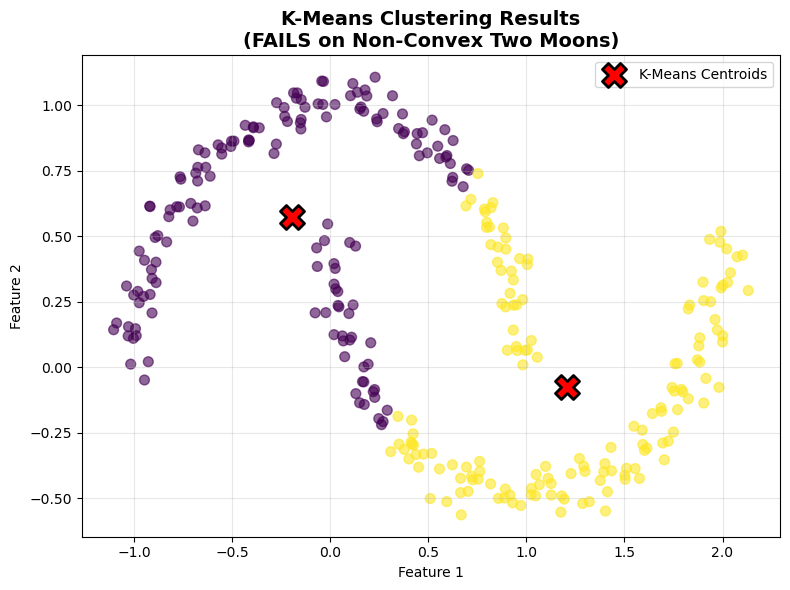

In [4]:
## Example Code Using scikit-learn
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans  # Changed from SpectralClustering to KMeans
from sklearn.datasets import make_moons

# Generate synthetic dataset (two moons - non-convex shape)
X, y = make_moons(n_samples=300, noise=0.05, random_state=42)

# Apply K-Means clustering (THIS WILL FAIL on non-convex shapes!)
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)  # Changed to KMeans
labels = kmeans.fit_predict(X)

# Plot the results
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', s=50, alpha=0.6)

# Plot K-means centroids
centroids = kmeans.cluster_centers_
plt.scatter(centroids[:, 0], centroids[:, 1], c='red', s=300, marker='X',
           edgecolors='black', linewidths=2, label='K-Means Centroids')

plt.title("K-Means Clustering Results\n(FAILS on Non-Convex Two Moons)", fontsize=14, fontweight='bold')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


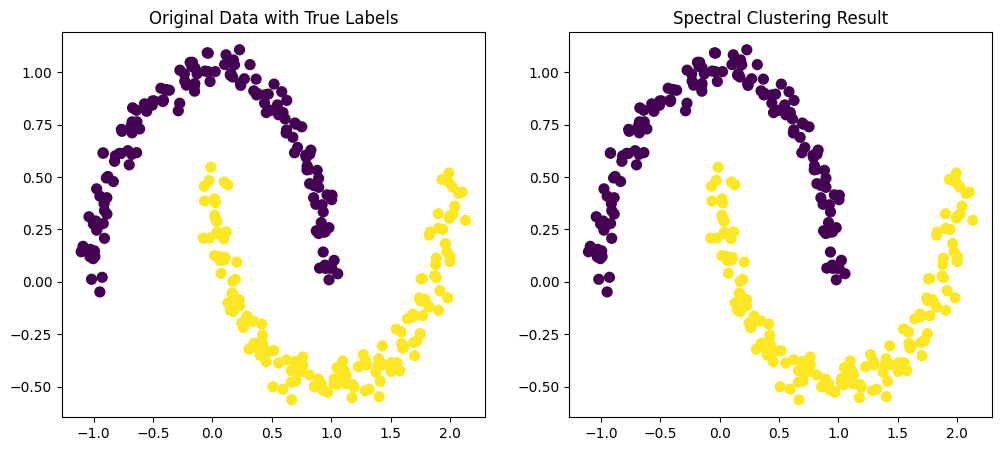

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.cluster import KMeans

# Step 1: Generate a synthetic dataset
# Using a two-moons dataset which has two non-linearly separable clusters
X, y = make_moons(n_samples=300, noise=0.05, random_state=42)

# Step 2: Create a similarity matrix using a Gaussian kernel
def compute_similarity_matrix(X, sigma=1.0):
    n_samples = X.shape[0]
    S = np.zeros((n_samples, n_samples))
    for i in range(n_samples):
        for j in range(n_samples):
            if i != j:
                # Gaussian similarity function
                S[i, j] = np.exp(-np.linalg.norm(X[i] - X[j]) ** 2 / (2 * sigma ** 2))
    return S

S = compute_similarity_matrix(X, sigma=0.1)

# Step 3: Compute the Laplacian matrix
D = np.diag(S.sum(axis=1))  # Degree matrix
L = D - S                   # Unnormalized Laplacian

# Step 4: Compute the first k eigenvectors of the Laplacian matrix
k = 2  # Number of clusters we want
eigenvalues, eigenvectors = np.linalg.eigh(L)
# Sort eigenvectors by their corresponding eigenvalues in ascending order
sorted_indices = np.argsort(eigenvalues)
U = eigenvectors[:, sorted_indices[:k]]  # Select the first k eigenvectors

# Step 5: Normalize the rows of U to unit length (optional, for stability)
U = U / np.linalg.norm(U, axis=1, keepdims=True)

# Step 6: Apply K-means clustering to the rows of U
kmeans = KMeans(n_clusters=k, random_state=42)
labels = kmeans.fit_predict(U)

# Step 7: Visualize the clustering result
plt.figure(figsize=(12, 5))

# Original dataset with true labels
plt.subplot(1, 2, 1)
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='viridis', s=50)
plt.title("Original Data with True Labels")

# Spectral clustering result
plt.subplot(1, 2, 2)
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', s=50)
plt.title("Spectral Clustering Result")

plt.show()


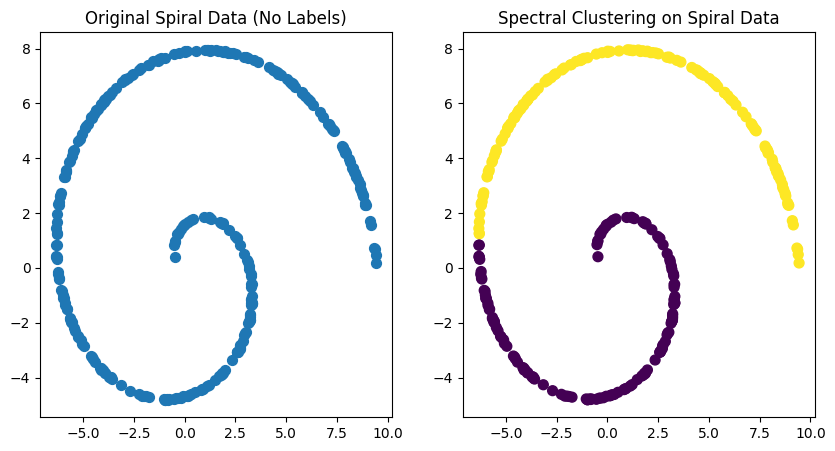

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import SpectralClustering

# Generate a spiral dataset
def generate_spiral_data(n_points, noise=0.05):
    n = np.sqrt(np.random.rand(n_points)) * 540 * (2 * np.pi) / 360
    x = -np.cos(n) * n + np.random.rand(n_points) * noise
    y = np.sin(n) * n + np.random.rand(n_points) * noise
    return np.vstack((x, y)).T

# Create spiral dataset
X = generate_spiral_data(300)

# Apply spectral clustering
spectral_clustering = SpectralClustering(n_clusters=2, affinity='nearest_neighbors', random_state=42)
y_spectral = spectral_clustering.fit_predict(X)

# Plot the results
plt.figure(figsize=(10, 5))

# Plot original data without labels
plt.subplot(1, 2, 1)
plt.scatter(X[:, 0], X[:, 1], s=50)
plt.title("Original Spiral Data (No Labels)")

# Plot spectral clustering results
plt.subplot(1, 2, 2)
plt.scatter(X[:, 0], X[:, 1], c=y_spectral, cmap='viridis', s=50)
plt.title("Spectral Clustering on Spiral Data")

plt.show()
